In [1]:
import torch
import matplotlib.pyplot as plt
from torch import nn

torch.manual_seed(0)

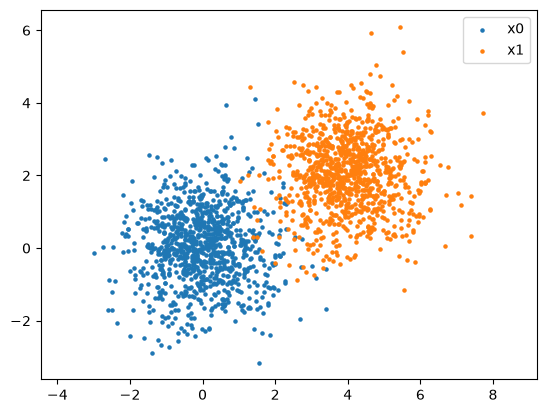

In [2]:
n = 1000

x0 = torch.randn(n, 2)
x1 = x0 + torch.tensor([4.0, 2.0])

plt.scatter(x0[:, 0], x0[:, 1], s=5, label="x0")
plt.scatter(x1[:, 0], x1[:, 1], s=5, label="x1")

plt.axis("equal")
plt.legend()
plt.show()

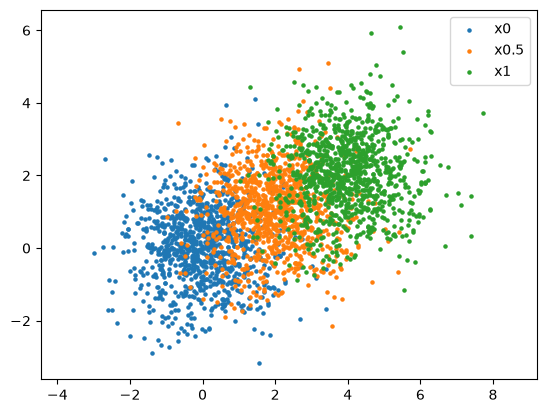

In [3]:
t = 0.5

x_half = (1 - t) * x0 + t * x1

plt.scatter(x0[:, 0], x0[:, 1], s=5, label="x0")
plt.scatter(x_half[:, 0], x_half[:, 1], s=5, label="x0.5")
plt.scatter(x1[:, 0], x1[:, 1], s=5, label="x1")

plt.axis("equal")
plt.legend()
plt.show()

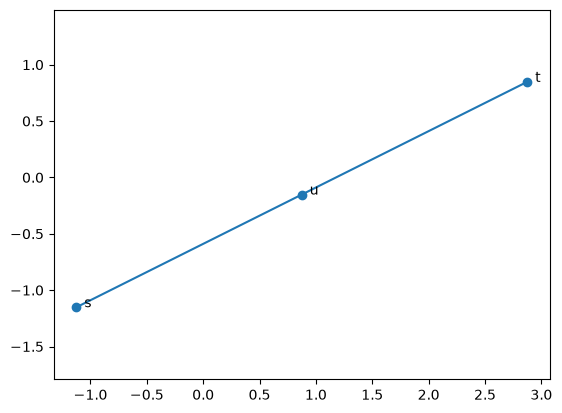

In [4]:
s = 0.0
u = 0.5
t = 1.0

x_s = (1 - s) * x0 + s * x1
x_u = (1 - u) * x0 + u * x1
x_t = (1 - t) * x0 + t * x1

i = 0

plt.plot(
    [x_s[i, 0], x_u[i, 0], x_t[i, 0]],
    [x_s[i, 1], x_u[i, 1], x_t[i, 1]],
    marker="o",
)

plt.text(x_s[i, 0], x_s[i, 1], "  s")
plt.text(x_u[i, 0], x_u[i, 1], "  u")
plt.text(x_t[i, 0], x_t[i, 1], "  t")

plt.axis("equal")
plt.show()

In [5]:
class FlowMap(nn.Module):
    def __init__(self, dim=2, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim + 2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, x, s, t):
        inp = torch.cat([x, s, t], dim=-1)
        return self.net(inp)

In [6]:
import copy

student = FlowMap()
teacher = copy.deepcopy(student)

for param in teacher.parameters():
    param.requires_grad_(False)

In [7]:
@torch.no_grad()
def update_teacher(student, teacher, decay=0.99):
    for student_param, teacher_param in zip(
        student.parameters(),
        teacher.parameters(),
    ):
        teacher_param.data.mul_(decay)
        teacher_param.data.add_(
            student_param.data,
            alpha=1 - decay,
        )

In [8]:
batch_size = 256

x0_batch = torch.randn(batch_size, 2)
x1_batch = x0_batch + torch.tensor([4.0, 2.0])

s = torch.zeros(batch_size, 1)
u = torch.full((batch_size, 1), 0.5)
t = torch.ones(batch_size, 1)

# student: long map s -> t
student_pred = student(x0_batch, s, t)

# teacher: two shorter maps s -> u -> t
with torch.no_grad():
    x_u_teacher = teacher(x0_batch, s, u)
    teacher_target = teacher(x_u_teacher, u, t)

print("student:", student_pred.shape)
print("teacher target:", teacher_target.shape)

student: torch.Size([256, 2])
teacher target: torch.Size([256, 2])


In [9]:
loss = (student_pred - teacher_target).pow(2).mean()

print("distillation loss:", loss.item())

distillation loss: 0.002666207030415535


In [10]:
optimizer = torch.optim.Adam(student.parameters(), lr=1e-3)

optimizer.zero_grad()
loss.backward()
optimizer.step()

update_teacher(student, teacher)

print("one training step done")

one training step done


In [11]:
x = torch.randn(1000, 2)
s = torch.rand(1000, 1)

with torch.no_grad():
    x_same = student(x, s, s)

identity_error = (x_same - x).pow(2).mean()

print("identity error:", identity_error.item())

identity error: 0.9874998331069946


In [12]:
def identity_loss(model, x, s):
    pred = model(x, s, s)

    return (pred - x).pow(2).mean()

In [13]:
optimizer = torch.optim.Adam(student.parameters(), lr=1e-3)

losses = []

for step in range(2000):
    batch_size = 256

    x = torch.randn(batch_size, 2)

    s = torch.zeros(batch_size, 1)
    u = torch.full((batch_size, 1), 0.5)
    t = torch.ones(batch_size, 1)

    # teacher: 0 -> 0.5 -> 1
    with torch.no_grad():
        x_u_teacher = teacher(x, s, u)
        teacher_target = teacher(x_u_teacher, u, t)

    # student: 0 -> 1
    student_pred = student(x, s, t)

    distill = (student_pred - teacher_target).pow(2).mean()

    # identity boundary condition
    s_id = torch.rand(batch_size, 1)
    identity = identity_loss(student, x, s_id)

    loss = distill + identity

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    update_teacher(student, teacher)

    losses.append(loss.item())

    if step % 200 == 0:
        print(
            f"step {step:4d} | "
            f"loss {loss.item():.6f} | "
            f"distill {distill.item():.6f} | "
            f"identity {identity.item():.6f}"
        )

step    0 | loss 1.034126 | distill 0.000603 | identity 1.033523
step  200 | loss 0.000691 | distill 0.000467 | identity 0.000223
step  400 | loss 0.000157 | distill 0.000101 | identity 0.000056
step  600 | loss 0.000067 | distill 0.000039 | identity 0.000028
step  800 | loss 0.000035 | distill 0.000021 | identity 0.000015
step 1000 | loss 0.000028 | distill 0.000015 | identity 0.000013
step 1200 | loss 0.000027 | distill 0.000013 | identity 0.000013
step 1400 | loss 0.000017 | distill 0.000008 | identity 0.000009
step 1600 | loss 0.000008 | distill 0.000003 | identity 0.000005
step 1800 | loss 0.000007 | distill 0.000003 | identity 0.000004


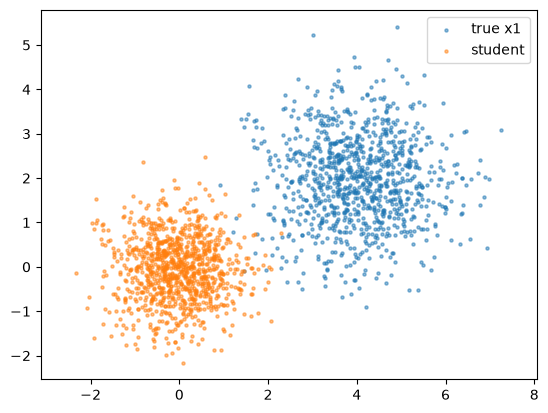

In [14]:
x0_test = torch.randn(1000, 2)

zero = torch.zeros(1000, 1)
one = torch.ones(1000, 1)

with torch.no_grad():
    x1_pred = student(x0_test, zero, one)

x1_true = x0_test + torch.tensor([4.0, 2.0])

plt.scatter(
    x1_true[:, 0],
    x1_true[:, 1],
    s=5,
    alpha=0.5,
    label="true x1",
)

plt.scatter(
    x1_pred[:, 0],
    x1_pred[:, 1],
    s=5,
    alpha=0.5,
    label="student",
)

plt.axis("equal")
plt.legend()
plt.show()

In [15]:
class FlowMap(nn.Module):
    def __init__(self, dim=2, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim + 2, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, dim),
        )

    def velocity(self, x, s, t):
        inp = torch.cat([x, s, t], dim=-1)
        return self.net(inp)

    def forward(self, x, s, t):
        v = self.velocity(x, s, t)
        return x + (t - s) * v

In [16]:
model = FlowMap()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

batch_size = 256

x0_batch = torch.randn(batch_size, 2)
x1_batch = x0_batch + torch.tensor([4.0, 2.0])

t = torch.rand(batch_size, 1)

x_t = (1 - t) * x0_batch + t * x1_batch

# true velocity of our interpolant
v_true = x1_batch - x0_batch

# diagonal velocity prediction: s = t
v_pred = model.velocity(x_t, t, t)

diagonal_loss = (v_pred - v_true).pow(2).mean()

print("diagonal loss:", diagonal_loss.item())

diagonal loss: 9.812962532043457


In [17]:
losses = []

for step in range(1000):
    batch_size = 256

    x0_batch = torch.randn(batch_size, 2)
    x1_batch = x0_batch + torch.tensor([4.0, 2.0])

    t = torch.rand(batch_size, 1)

    x_t = (1 - t) * x0_batch + t * x1_batch
    v_true = x1_batch - x0_batch

    v_pred = model.velocity(x_t, t, t)

    loss = (v_pred - v_true).pow(2).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 100 == 0:
        print(f"step {step:4d} | diagonal loss {loss.item():.6f}")

step    0 | diagonal loss 9.815372
step  100 | diagonal loss 0.024740
step  200 | diagonal loss 0.001864
step  300 | diagonal loss 0.000528
step  400 | diagonal loss 0.000388
step  500 | diagonal loss 0.000221
step  600 | diagonal loss 0.000153
step  700 | diagonal loss 0.000091
step  800 | diagonal loss 0.000057
step  900 | diagonal loss 0.000039


In [18]:
x_test = torch.randn(1000, 2)
t_test = torch.rand(1000, 1)

x_t_test = x_test + t_test * torch.tensor([4.0, 2.0])

with torch.no_grad():
    v_pred = model.velocity(x_t_test, t_test, t_test)

print("mean predicted velocity:", v_pred.mean(dim=0))

mean predicted velocity: tensor([4.0005, 2.0000])


In [19]:
x0_test = torch.randn(1000, 2)

zero = torch.zeros(1000, 1)
one = torch.ones(1000, 1)

with torch.no_grad():
    x1_pred = model(x0_test, zero, one)

x1_true = x0_test + torch.tensor([4.0, 2.0])

error = (x1_pred - x1_true).pow(2).mean()

print("0 -> 1 error:", error.item())

0 -> 1 error: 0.013050347566604614


In [20]:
import copy

teacher = copy.deepcopy(model)

for param in teacher.parameters():
    param.requires_grad_(False)

student = copy.deepcopy(model)

optimizer = torch.optim.Adam(student.parameters(), lr=1e-3)

In [21]:
batch_size = 256

x0_batch = torch.randn(batch_size, 2)
x1_batch = x0_batch + torch.tensor([4.0, 2.0])

s = torch.rand(batch_size, 1)
t = s + (1 - s) * torch.rand(batch_size, 1)

x_s = (1 - s) * x0_batch + s * x1_batch

print("s:", s[:5].squeeze())
print("t:", t[:5].squeeze())

s: tensor([0.8889, 0.8485, 0.6618, 0.9936, 0.7541])
t: tensor([0.9629, 0.9503, 0.8885, 0.9945, 0.9110])


In [22]:
delta = 0.05

u = torch.minimum(
    s + delta,
    t,
)

with torch.no_grad():
    v_teacher = teacher.velocity(x_s, s, s)

    x_u_teacher = x_s + (u - s) * v_teacher

print("teacher velocity mean:", v_teacher.mean(dim=0))
print("mean step size:", (u - s).mean().item())

teacher velocity mean: tensor([4.0012, 2.0008])
mean step size: 0.04450368508696556


In [23]:
with torch.no_grad():
    teacher_target = teacher(
        x_u_teacher,
        u,
        t,
    )

student_pred = student(
    x_s,
    s,
    t,
)

distill_loss = (
    student_pred - teacher_target
).pow(2).mean()

print("distillation loss:", distill_loss.item())

distillation loss: 1.0884585208259523e-05


In [24]:
optimizer.zero_grad()
distill_loss.backward()
optimizer.step()

print("one self-distillation step done")

one self-distillation step done


## Grounded self-distillation

Consistency alone does not identify the correct flow.
We first learn the local velocity on the diagonal, then use this
grounded local information to distill longer flow maps.

In [25]:
model = FlowMap()
teacher = copy.deepcopy(model)

for param in teacher.parameters():
    param.requires_grad_(False)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []

for step in range(2000):
    batch_size = 256

    x0_batch = torch.randn(batch_size, 2)
    x1_batch = x0_batch + torch.tensor([4.0, 2.0])

    # --------------------------------------------------
    # 1. Diagonal supervision
    # --------------------------------------------------

    r = torch.rand(batch_size, 1)

    x_r = (1 - r) * x0_batch + r * x1_batch
    v_true = x1_batch - x0_batch

    v_pred = model.velocity(x_r, r, r)

    diagonal_loss = (v_pred - v_true).pow(2).mean()

    # --------------------------------------------------
    # 2. Off-diagonal self-distillation
    # --------------------------------------------------

    s = torch.rand(batch_size, 1)
    t = s + (1 - s) * torch.rand(batch_size, 1)

    x_s = (1 - s) * x0_batch + s * x1_batch

    u = torch.minimum(
        s + 0.05,
        t,
    )

    with torch.no_grad():
        # grounded local step
        v_teacher = teacher.velocity(x_s, s, s)
        x_u = x_s + (u - s) * v_teacher

        # teacher completes u -> t
        teacher_target = teacher(x_u, u, t)

    student_pred = model(x_s, s, t)

    distill_loss = (
        student_pred - teacher_target
    ).pow(2).mean()

    # --------------------------------------------------
    # Total
    # --------------------------------------------------

    loss = diagonal_loss + distill_loss

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    update_teacher(model, teacher)

    losses.append(loss.item())

    if step % 200 == 0:
        print(
            f"step {step:4d} | "
            f"loss {loss.item():.6f} | "
            f"diagonal {diagonal_loss.item():.6f} | "
            f"distill {distill_loss.item():.6f}"
        )

step    0 | loss 10.418469 | diagonal 10.418469 | distill 0.000000
step  200 | loss 0.025535 | diagonal 0.007330 | distill 0.018205
step  400 | loss 0.001018 | diagonal 0.000694 | distill 0.000324
step  600 | loss 0.000649 | diagonal 0.000391 | distill 0.000258
step  800 | loss 0.000421 | diagonal 0.000239 | distill 0.000182
step 1000 | loss 0.000243 | diagonal 0.000140 | distill 0.000102
step 1200 | loss 0.000181 | diagonal 0.000102 | distill 0.000079
step 1400 | loss 0.000084 | diagonal 0.000053 | distill 0.000031
step 1600 | loss 0.000061 | diagonal 0.000041 | distill 0.000020
step 1800 | loss 0.000037 | diagonal 0.000025 | distill 0.000012


0 -> 1 error: 0.04129914939403534


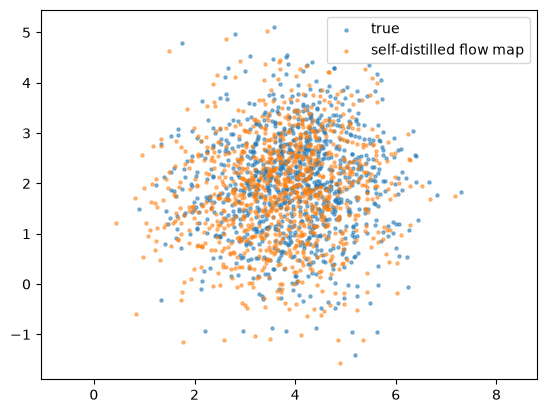

In [26]:
x0_test = torch.randn(1000, 2)

zero = torch.zeros(1000, 1)
one = torch.ones(1000, 1)

with torch.no_grad():
    x1_pred = model(x0_test, zero, one)

x1_true = x0_test + torch.tensor([4.0, 2.0])

error = (x1_pred - x1_true).pow(2).mean()

print("0 -> 1 error:", error.item())

plt.scatter(
    x1_true[:, 0],
    x1_true[:, 1],
    s=5,
    alpha=0.5,
    label="true",
)

plt.scatter(
    x1_pred[:, 0],
    x1_pred[:, 1],
    s=5,
    alpha=0.5,
    label="self-distilled flow map",
)

plt.axis("equal")
plt.legend()
plt.show()